# HW05.2 — NumPy Multi-Layer Perceptron

Portfolio edition by Behrad Mazaheri. The upload contains implemented neural-network primitives but omits the `utils` modules. Replacement numerical-gradient, data and solver utilities are added in this edition; see README for provenance.


# Overview: Building a Neural Network Framework with NumPy

In this assignment, you will build a simple **Multi-Layer Perceptron (MLP) framework** using only NumPy. By implementing each component step by step, you will gain a fundamental understanding of **forward and backward propagation**, **loss functions**, and **optimization techniques**.

Each part of the assignment builds on the previous one.

### Goal
To build a modular **Multi-Layer Perceptron (MLP)** framework using NumPy from scratch.

### Structure of the Assignment

Each section below builds towards the final goal of training an MLP. The first steps focus on implementing fundamental components, while later steps involve integrating them into a complete training pipeline.

#### **Step 1: Implementing Core Functions (70 points)**
- **Forward & Backward Passes (10 points):** Implement `affine_forward` and `affine_backward` to compute layer outputs and gradients.
- **Activation Functions (20 points):** Implement ReLU and Sigmoid functions (`relu_forward/backward`, `sigmoid_forward/backward`).
- **Loss Calculation (15 points):** Implement `mse_loss` to compute Mean Squared Error and its gradient.
- **Building a Multi-Layer Network (15 points):** Define a `FullyConnectedNet` class that integrates all layers and computes forward and backward passes.
- **Optimization (10 points):** Implement `sgd_momentum` to update parameters.

#### **Step 2: Training & Evaluation (30 points)**
- **Training (25 points):** Train the `FullyConnectedNet` using a `Solver` class.
- **Evaluation (5 points):** Assess the model on validation/test data.
**__Your score on this section is based on the result of your model and defines how well the previous sections are implemented.__*

Install dependencies from `requirements.txt`. Training and differentiation use NumPy; no PyTorch or torchvision is required.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from support import eval_numerical_gradient, eval_numerical_gradient_array, load_housing, split_and_normalize, Solver
plt.rcParams['figure.figsize'] = (10.0, 6.0)
np.random.seed(42)

def rel_error(x,y):
    return np.max(np.abs(x-y)/np.maximum(1e-8,np.abs(x)+np.abs(y)))


# Fully-Connected Neural Nets
In this exercise we will implement fully-connected networks using a modular approach. For each layer we will implement a generic `forward` and a `backward` function. The `forward` function will receive inputs, weights, and other parameters and will return both an output and a `cache` object storing data needed for the backward pass, like this:

```python
def layer_forward(x, w):
  """ Receive inputs x and weights w """
  # Do some computations ...
  z = # ... some intermediate value
  # Do some more computations ...
  out = # the output
   
  cache = (x, w, z, out) # Values we need to compute gradients
   
  return out, cache
```

The backward pass will receive upstream derivatives and the `cache` object, and will return gradients with respect to the inputs and weights, like this:

```python
def layer_backward(dout, cache):
  """
  Receive dout (derivative of loss with respect to outputs) and cache,
  and compute derivative with respect to inputs.
  """
  # Unpack cache values
  x, w, z, out = cache
  
  # Use values in cache to compute derivatives
  dx = # Derivative of loss with respect to x
  dw = # Derivative of loss with respect to w
  
  return dx, dw
```

After implementing a bunch of layers this way, we will be able to easily combine them to build different models with architectures.

# Affine layer: forward (5 Points)
Implement the `affine_forward` function.

In [2]:
def affine_forward(x, w, b):
    ###########################################################################
    # TODO: Implement the affine forward pass. Store the result in out. You   #
    # will need to reshape the input into rows.                               #
    ###########################################################################
    # *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
    x_reshaped = x.reshape(x.shape[0], -1)  # Reshape to (N, D)
    out = x_reshaped.dot(w) + b  # compute out
    cache = (x, w, b)  # Values we need to compute gradients

    # *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
    ###########################################################################
    #                             END OF YOUR CODE                            #
    ###########################################################################
    return out, cache


You can test your implementaion by running the following:

In [3]:
# Test the affine_forward function

num_inputs = 2
input_shape = (4, 5, 6)
output_dim = 3

input_size = num_inputs * np.prod(input_shape)
weight_size = output_dim * np.prod(input_shape)

x = np.linspace(-0.1, 0.5, num=input_size).reshape(num_inputs, *input_shape)
w = np.linspace(-0.2, 0.3, num=weight_size).reshape(np.prod(input_shape), output_dim)
b = np.linspace(-0.3, 0.1, num=output_dim)

out, _ = affine_forward(x, w, b)
correct_out = np.array([[ 1.49834967,  1.70660132,  1.91485297],
                        [ 3.25553199,  3.5141327,   3.77273342]])


# Compare your output with ours. The error should be around e-9 or less.
print('Testing affine_forward function:')
print('difference: ', rel_error(out, correct_out))

Testing affine_forward function:
difference:  9.769848888397517e-10


# Affine layer: backward (5 Points)
Now implement the `affine_backward` function and test your implementation using numeric gradient checking.


Given an affine transformation in a neural network:

$
Z = XW + b
$

where:
- $ X $ is the input matrix of shape $ (N, D) $
- $ W $ is the weight matrix of shape $ (D, M) $
- $ b $ is the bias vector of shape $ (1, M) $
- $ Z $ is the output before activation of shape $ (N, M) $

### Backward Pass Gradients:

1. **Gradient w.r.t. input $ X $:**
 $
   dX = dZ W^T
$
   (Shape: $ (N, D) $)

2. **Gradient w.r.t. weights $ W $:**
   $
   dW = X^T dZ
   $
   (Shape: $ (D, M) $)

3. **Gradient w.r.t. bias $ b $:**
   $
   db = \sum_{i=1}^{N} dZ_i
   $
   (Shape: $ (1, M) $)


In [4]:
def affine_backward(dout, cache):
    ###########################################################################
    # TODO: Implement the affine backward pass.                               #
    ###########################################################################
    # *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
    x, w, b = cache
    N = x.shape[0]
    M = w.shape[1]

    #assert dout.shape == (N,M)

    # Reshape x to 2D if it's not already
    x_reshaped = x.reshape(N, -1)
    
    dx = dout.dot(w.T)  # Derivative of loss with respect to x
    dx = dx.reshape(x.shape)  # Reshape back to original shape
    
    dw = x_reshaped.T.dot(dout)  # Derivative of loss with respect to w
    db = np.sum(dout, axis=0)  # Derivative of loss with respect to b

    # *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
    ###########################################################################
    #                             END OF YOUR CODE                            #
    ###########################################################################
    return dx, dw, db

In [5]:
# Test the affine_backward function
np.random.seed(231)
x = np.random.randn(10, 2, 3)
w = np.random.randn(6, 5)
b = np.random.randn(5)
dout = np.random.randn(10, 5)

dx_num = eval_numerical_gradient_array(lambda x: affine_forward(x, w, b)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: affine_forward(x, w, b)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: affine_forward(x, w, b)[0], b, dout)

_, cache = affine_forward(x, w, b)
dx, dw, db = affine_backward(dout, cache)

# The error should be around e-10 or less
print('Testing affine_backward function:')
print('dx error: ', rel_error(dx_num, dx))
print('dw error: ', rel_error(dw_num, dw))
print('db error: ', rel_error(db_num, db))

Testing affine_backward function:
dx error:  4.628092225390844e-09
dw error:  4.169220174478563e-10
db error:  2.8827924947094148e-11


# ReLU activation: forward (5 Points)
Implement the forward pass for the ReLU activation function in the `relu_forward` function and test your implementation using numeric gradient checking.

In [6]:
def relu_forward(x):
    ###########################################################################
    # TODO: Implement the ReLU forward pass.                                  #
    ###########################################################################
    # *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
    out = np.maximum(0, x)  # compute ReLU(x)
    cache = x

    # *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
    ###########################################################################
    #                             END OF YOUR CODE                            #
    ###########################################################################
    return out, cache

In [7]:
# Test the relu_forward function

x = np.linspace(-0.5, 0.5, num=12).reshape(3, 4)

out, _ = relu_forward(x)
correct_out = np.array([[ 0.,          0.,          0.,          0.,        ],
                        [ 0.,          0.,          0.04545455,  0.13636364,],
                        [ 0.22727273,  0.31818182,  0.40909091,  0.5,       ]])

# Compare your output with ours. The error should be on the order of e-8
print('Testing relu_forward function:')
print('difference: ', rel_error(out, correct_out))

Testing relu_forward function:
difference:  4.999999798022158e-08


# ReLU activation: backward (5 Points)
Now implement the backward pass for the ReLU activation function in the `relu_backward` function.


ReLU Activation Backward Pass:

Given the ReLU activation function:

$ A = \max(0, Z) $

where $ A $ is the output after activation, and $ Z $ is the pre-activation input.

1. **Gradient w.r.t. pre-activation input $ Z $:**
   $
   dZ = dA \cdot \mathbb{1}(Z > 0)
   $
   
   (Element-wise multiplication where $ \mathbb{1}(Z > 0) $ is an indicator function that is $1$ when $ Z > 0 $ and 0 otherwise.)

In [8]:
def relu_backward(dout, cache):
    ###########################################################################
    # TODO: Implement the ReLU backward pass.                                 #
    ###########################################################################
    # *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
    dx = dout * (cache > 0)  # Derivative of loss with respect to x

    # *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
    ###########################################################################
    #                             END OF YOUR CODE                            #
    ###########################################################################
    return dx

You can test your implementation using numeric gradient checking:

In [9]:
# Test the relu_backward function
np.random.seed(231)
x = np.random.randn(10, 10)
dout = np.random.randn(*x.shape)

dx_num = eval_numerical_gradient_array(lambda x: relu_forward(x)[0], x, dout)

_, cache = relu_forward(x)
dx = relu_backward(dout, cache)

# The error should be on the order of e-12
print('Testing relu_backward function:')
print('dx error: ', rel_error(dx_num, dx))

Testing relu_backward function:
dx error:  4.710307455630476e-09


# Sigmoid activation: forward (5 Points)
Implement the forward pass for the Sigmoid activation function in the `sigmoid_forward` function and test your implementation using numeric gradient checking.

In [10]:
def sigmoid_forward(x):
    x = np.asarray(x,dtype=float)
    out = np.empty_like(x)
    mask = x >= 0
    out[mask] = 1 / (1 + np.exp(-x[mask]))
    exponent = np.exp(x[~mask])
    out[~mask] = exponent / (1 + exponent)
    return out, x


In [11]:
# Test the sigmoid_forward function

x = np.linspace(-6, 6, num=12).reshape(3, 4)

out, _ = sigmoid_forward(x)
correct_out = np.array([[0.00247262, 0.00732514, 0.0214955 , 0.06138311],
                        [0.16296047, 0.36691963, 0.63308037, 0.83703953],
                        [0.93861689, 0.9785045 , 0.99267486, 0.99752738]])

# Compare your output with ours. The error should be on the order of e-7
print('Testing sigmoid_forward function:')
print('difference: ', rel_error(out, correct_out))

Testing sigmoid_forward function:
difference:  6.383174041736893e-07


# Sigmoid activation: backward (5 Points)
Now implement the backward pass for the Sigmoid activation function in the `sigmoid_backward` function.

Given the Sigmoid activation function:

$
A = \sigma(Z) = \frac{1}{1 + e^{-Z}}
$

where $ A $ is the output after activation, and $ Z $ is the pre-activation input.

The derivative of the Sigmoid function is:

$
\frac{dA}{dZ} = \sigma(Z) (1 - \sigma(Z))
$

The backward pass computes the gradient:

1. **Gradient w.r.t. pre-activation input $ Z $:**
   $
   dZ = dA \cdot \sigma(Z) (1 - \sigma(Z))
   $
   
   (Element-wise multiplication using the derivative of Sigmoid.)


In [12]:
def sigmoid_backward(dout,cache):
    out,_ = sigmoid_forward(cache)
    return dout*out*(1-out)


You can test your implementation using numeric gradient checking:

In [13]:
# Test the sigmoid_backward function
np.random.seed(231)
x = np.random.randn(10, 10)
dout = np.random.randn(*x.shape)

dx_num = eval_numerical_gradient_array(lambda x: sigmoid_forward(x)[0], x, dout)

_, cache = sigmoid_forward(x)
dx = sigmoid_backward(dout, cache)

# The error should be on the order of e-11
print('Testing sigmoid_backward function:')
print('dx error: ', rel_error(dx_num, dx))

Testing sigmoid_backward function:
dx error:  7.0384032605602354e-09


# Loss layer: MSE (15 Points)
Now implement the loss and gradient for mean squared error in the `mse_loss` function.

In [14]:
def mse_loss(x,y):
    x,y = np.asarray(x),np.asarray(y)
    if x.size == 0:
        raise ValueError("MSE requires nonempty predictions")
    if x.shape != y.shape:
        # Permit equivalent scalar-regression vector/column shapes only.
        if x.ndim == 2 and x.shape[1] == 1 and y.shape == (x.shape[0],):
            y = y.reshape(x.shape)
        elif x.ndim == 1 and y.shape == (x.shape[0],1):
            y = y.reshape(x.shape)
        else:
            raise ValueError("Prediction and target shapes must match")
    difference = x-y
    return float(np.mean(difference**2)), 2*difference/x.size


You can make sure that the implementations are correct by running the following:

In [15]:
np.random.seed(231)
num_inputs = 50
x = np.random.randn(num_inputs)
y = np.random.randn(num_inputs)

dx_num = eval_numerical_gradient(lambda x: mse_loss(x, y)[0], x, verbose=False)
loss, dx = mse_loss(x, y)

# Test mse_loss function. Loss should be close to 1.9 and dx error should be around e-9
print('\nTesting mse_loss:')
print('loss: ', loss)
print('dx error: ', rel_error(dx_num, dx))


Testing mse_loss:
loss:  1.8672282748726519
dx error:  2.8607953262121067e-09


# Multi-Layer Fully Connected Network (15 Points)
In this part, you will implement a fully connected network with an arbitrary number of hidden layers.

In [16]:
class FullyConnectedNet(object):
    """Regression MLP: hidden affine/ReLU blocks, linear output, MSE + L2.

    No classification or softmax implementation is provided.
    """

    def __init__(
        self,
        hidden_dims,
        input_dim=8,
        output_dim=1,
        reg=0.0,
        weight_scale=1e-2,
        dtype=np.float32,
    ):
        """Initialize a new FullyConnectedNet.

        Inputs:

        - hidden_dims: A list of integers giving the size of each hidden layer.
        - input_dim: An integer giving the size of the input.
        - output_dim: An integer giving the number of regression outputs. It
            is 1 for a regression problem.
        - reg: Scalar giving L2 regularization strength.
        - weight_scale: Scalar giving the standard deviation for random
            initialization of the weights.
        - dtype: A numpy datatype object; all computations will be performed using
            this datatype. float32 is faster but less accurate, so you should use
            float64 for numeric gradient checking.
        """
        self.category = 'regression'
        self.reg = reg
        self.num_layers = 1 + len(hidden_dims)
        self.dtype = dtype
        self.params = {}

        ############################################################################
        # TODO: Initialize the parameters of the network, storing all values in    #
        # the self.params dictionary. Store weights and biases for the first layer #
        # in W1 and b1; for the second layer use W2 and b2, etc. Weights should be #
        # initialized from a normal distribution centered at 0 with standard       #
        # deviation equal to weight_scale. Biases should be initialized to zero.   #
        #                                                                          #
        ############################################################################
        # *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****

        # Initialize parameters
        dims = [input_dim] + list(hidden_dims) + [output_dim]
    
        for i in range(self.num_layers):
            self.params['W' + str(i+1)] = weight_scale * np.random.randn(dims[i], dims[i+1])
            self.params['b' + str(i+1)] = np.zeros(dims[i+1])


        # *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
        ############################################################################
        #                             END OF YOUR CODE                             #
        ############################################################################


        # Cast all parameters to the correct datatype.
        for k, v in self.params.items():
            self.params[k] = v.astype(dtype)

    def loss(self, X, y=None):
        """Compute loss and gradient for the fully connected net.

        Inputs:
        - X: Array of input data of shape (N, d_1, ..., d_k)
        - y: Array of labels / target values, of shape (N,). y[i] gives the
            label / target value for X[i].
        - show_distributions: Boolean that if enabled and y in none, show output
        of each layer to see effects of diffrent approaches

        Returns:
        If y is None, then run a test-time forward pass of the model and return
        scores for a classification problem or the predicted_values for
        a regression problem:
        - out: Array of shape (N, C) / (N, ) giving classification scores / predicted values, where
        scores[i, c] is the classification score for X[i] and class c / predicted_values[i]
        is the predicted value for X[i].


        If y is not None, then run a training-time forward and backward pass and
        return a tuple of:
        - loss: Scalar value giving the loss
        - grads: Dictionary with the same keys as self.params, mapping parameter
            names to gradients of the loss with respect to those parameters.
        """
        X = X.astype(self.dtype)
        mode = "test" if y is None else "train"

        ############################################################################
        # TODO: Implement the forward pass for the fully connected net, computing  #
        # the class scores / target values for X and storing them in the out       #
        #  variable.                                                               #
        #                                                                          #
        ############################################################################
        # *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****

        out = X
        self.layer_cache = {}
        layer_outputs = []  # Store layer outputs for visualization
        for i in range(self.num_layers - 1):
              out, cache = affine_forward(out, self.params['W' + str(i+1)], self.params['b' + str(i+1)])
              self.layer_cache['affine' + str(i+1)] = cache
        
              out, cache = relu_forward(out)
              self.layer_cache['relu' + str(i+1)] = cache
              layer_outputs.append(out)  # Save output for visualization

    # Forward through output layer
        out, cache = affine_forward(out, self.params['W' + str(self.num_layers)], self.params['b' + str(self.num_layers)])
        self.layer_cache['affine' + str(self.num_layers)] = cache
        layer_outputs.append(out)
        # Save output for visualization

        # *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
        ############################################################################
        #                             END OF YOUR CODE                             #
        ############################################################################

        # If test mode return early.
        if mode == "test":
            return out

        loss, grads = 0.0, {}
        ############################################################################
        # TODO: Implement the backward pass for the fully connected net. Store the #
        # loss in the loss variable and gradients in the grads dictionary. Compute #
        # data loss using mse, and make sure that grads[k] holds the               #
        # gradients for self.params[k]. Don't forget to add L2 regularization!     #
        #                                                                          #
        #                                                                          #
        # NOTE: To ensure that your implementation matches ours and you pass the   #
        # automated tests, make sure that your L2 regularization includes a factor #
        # of 0.5 to simplify the expression for the gradient.                      #
        ############################################################################
        # *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****

        # compute loss
        loss, dout = mse_loss(out, y)

        # Regularization
        reg_loss = 0
        for i in range(self.num_layers):
            W = self.params['W' + str(i+1)]
            reg_loss += 0.5 * self.reg * np.sum(W * W)
        loss += reg_loss

        # Backward pass
        # Backward through output layer
        dout, dw, db = affine_backward(dout, self.layer_cache['affine' + str(self.num_layers)])
        grads['W' + str(self.num_layers)] = dw + self.reg * self.params['W' + str(self.num_layers)]
        grads['b' + str(self.num_layers)] = db
        
        # Backward through hidden layers
        for i in range(self.num_layers - 2, -1, -1):
            dout = relu_backward(dout, self.layer_cache['relu' + str(i+1)])
            dout, dw, db = affine_backward(dout, self.layer_cache['affine' + str(i+1)])
            grads['W' + str(i+1)] = dw + self.reg * self.params['W' + str(i+1)]
            grads['b' + str(i+1)] = db
            # Regularization

        # Backpropagation affine

        # Regularization


        # *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
        ############################################################################
        #                             END OF YOUR CODE                             #
        ############################################################################

        return loss, grads

## Initial Loss and Gradient Check

As a sanity check, run the following to check the initial loss and to gradient check the network both with and without regularization. This is a good way to see if the initial losses seem reasonable.

For gradient checking, you should expect to see errors around 1e-7 or less.

In [17]:
np.random.seed(231)
N, D, H1, H2 = 2, 15, 20, 30
X = np.random.randn(N, D)
y = np.random.randint(123, size=(N,))

for reg in [0, 3.14]:
    print("Running check with reg = ", reg)
    model = FullyConnectedNet(
        [H1, H2],
        input_dim=D,
        output_dim=1,
        reg=reg,
        weight_scale=5e-2,
        dtype=np.float64
    )

    loss, grads = model.loss(X, y)
    print("Initial loss: ", loss)

    # Most of the errors should be on the order of e-7 or smaller.
    # NOTE: It is fine however to see an error for W2 on the order of e-5
    # for the check when reg = 0.0
    for name in sorted(grads):
        f = lambda _: model.loss(X, y)[0]
        grad_num = eval_numerical_gradient(f, model.params[name], verbose=False, h=1e-5)
        print(f"{name} relative error: {rel_error(grad_num, grads[name])}")

Running check with reg =  0
Initial loss:  5466.865706251272
W1 relative error: 5.635683954807205e-05
W2 relative error: 1.613210683498996e-05
W3 relative error: 6.898987504530194e-07
b1 relative error: 1.5616081970079422e-06
b2 relative error: 4.3057176756698825e-08
b3 relative error: 1.6746974192121475e-10
Running check with reg =  3.14
Initial loss:  5470.0372228262195
W1 relative error: 6.993826822383984e-06
W2 relative error: 0.0004837100232379589
W3 relative error: 1.0086922344670114e-05
b1 relative error: 2.626926800500172e-07
b2 relative error: 1.2120991887982816e-07
b3 relative error: 1.7983206598641928e-10


## SGD+Momentum (10 Points)
Stochastic gradient descent with momentum is a widely used update rule that tends to make deep networks converge faster than vanilla stochastic gradient descent.

Implement the SGD+momentum update rule in the function `sgd_momentum`.

### Question:
How does the behavior of the optimization process, specifically the trajectory through the loss landscape, differ when using Stochastic Gradient Descent (SGD) with momentum compared to using vanilla SGD?
Momentum accumulates a decaying velocity from previous gradients. Consistent directions accumulate larger steps, while alternating directions can partly cancel and reduce oscillation. It can overshoot when learning rate or momentum is too large; it does not guarantee a faster or better solution. Setting momentum to zero gives plain SGD.


In [18]:
def sgd_momentum(w, dw, config=None):
    """
    Performs stochastic gradient descent with momentum.
    Inputs:
    - w: A numpy array giving the current weights.
    - dw: A numpy array of the same shape as w giving the gradient of the
    loss with respect to w.
    - config: A dictionary containing hyperparameter values such as learning
    rate, momentum.

    Returns:
      - next_w: The next point after the update.
      - config: The config dictionary to be passed to the next iteration of the
        update rule.

    config format:
    - learning_rate: Scalar learning rate.
    - momentum: Scalar between 0 and 1 giving the momentum value.
      Setting momentum = 0 reduces sgd_momentum to stochastic gradient descent.
    - velocity: A numpy array of the same shape as w and dw used to store a
      moving average of the gradients.
    """
    if config is None:
        config = {}
    config.setdefault("learning_rate", 1e-2)
    config.setdefault("momentum", 0.9)
    v = config.get("velocity", np.zeros_like(w))

    next_w = None
    ###########################################################################
    # TODO: Implement the momentum update formula. Store the updated value in #
    # the next_w variable. You should also use and update the velocity v.     #
    ###########################################################################
    # *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****

    v = config["momentum"] * v - config["learning_rate"] * dw  # compute the velocity
    next_w = w + v  # update weights


    # *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
    ###########################################################################
    #                             END OF YOUR CODE                            #
    ###########################################################################
    config["velocity"] = v

    return next_w, config

Run the following to check your implementation. You should see errors less than e-8.

In [19]:
N, D = 4, 5
w = np.linspace(-0.4, 0.6, num=N*D).reshape(N, D)
dw = np.linspace(-0.6, 0.4, num=N*D).reshape(N, D)
v = np.linspace(0.6, 0.9, num=N*D).reshape(N, D)

config = {"learning_rate": 1e-3, "velocity": v}
next_w, _ = sgd_momentum(w, dw, config=config)

expected_next_w = np.asarray([
  [ 0.1406,      0.20738947,  0.27417895,  0.34096842,  0.40775789],
  [ 0.47454737,  0.54133684,  0.60812632,  0.67491579,  0.74170526],
  [ 0.80849474,  0.87528421,  0.94207368,  1.00886316,  1.07565263],
  [ 1.14244211,  1.20923158,  1.27602105,  1.34281053,  1.4096    ]])
expected_velocity = np.asarray([
  [ 0.5406,      0.55475789,  0.56891579, 0.58307368,  0.59723158],
  [ 0.61138947,  0.62554737,  0.63970526,  0.65386316,  0.66802105],
  [ 0.68217895,  0.69633684,  0.71049474,  0.72465263,  0.73881053],
  [ 0.75296842,  0.76712632,  0.78128421,  0.79544211,  0.8096    ]])

# Should see relative errors around e-8 or less
print("next_w error: ", rel_error(next_w, expected_next_w))
print("velocity error: ", rel_error(expected_velocity, config["velocity"]))

next_w error:  8.882347033505819e-09
velocity error:  4.269287743278663e-09


# Real World Application
Now that we have implemented the core functions and built a multilayer network, and tested it on random data to ensure it functions correctly, It is time to train the model on a real dataset. For this, we will use the California Housing dataset, which contains information about housing prices in different districts of California. The dataset includes features such as median income, house age, and population, making it a useful benchmark for regression tasks. Our goal is to train the network to predict house prices based on these features.

## California Housing data

This edition bundles the 20,640-row, eight-feature dataset loaded by scikit-learn's `fetch_california_housing`. The target is median district/block-group house value in units of $100,000, from 1990 census data. Training itself uses only NumPy. See `data/README.md` for origin and file integrity.


In [20]:
housing_X,housing_y,feature_names = load_housing()
print("Full dataset:",housing_X.shape,housing_y.shape)
print("Features:",feature_names)
print("First target values (continuous):",housing_y[:5])


Full dataset: (20640, 8) (20640,)
Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
First target values (continuous): [4.526 3.585 3.521 3.413 3.422]


In [21]:
data,normalization = split_and_normalize(housing_X,housing_y,seed=42)
for split in ["train","val","test"]:
    print(split,data["X_"+split].shape,data["y_"+split].shape)


train (14447, 8) (14447,)
val (3096, 8) (3096,)
test (3097, 8) (3097,)


In [22]:
# Statistics come from the training split only; all targets remain floating point.
print("Normalized training means:",data['X_train'].mean(axis=0))
print("Normalized training standard deviations:",data['X_train'].std(axis=0))
print("Target training mean / standard deviation:",normalization['y_mean'],normalization['y_std'])


Normalized training means: [ 3.48561769e-15  2.43915545e-17  2.92710950e-15 -5.95669580e-15
 -4.73229971e-17  5.25263750e-16 -2.96222442e-14 -2.59497814e-13]
Normalized training standard deviations: [1. 1. 1. 1. 1. 1. 1. 1.]
Target training mean / standard deviation: 2.0758774679864334 1.1552931388012404


## Training

Use a fixed two-hidden-layer regression MLP. The replacement Solver trains on minibatches, reports full train/validation MSE each epoch, and restores the parameters from the lowest-validation-MSE epoch. The held-out test split is not used for checkpoint selection. Training uses standardized targets; reported final regression metrics are transformed back to the original target units.


In [23]:
np.random.seed(42)
model = FullyConnectedNet([100,50],input_dim=8,output_dim=1,reg=1e-4,weight_scale=.05,dtype=np.float64)
solver = Solver(model,data,update_rule=sgd_momentum,
                optim_config={'learning_rate':.01,'momentum':.9},lr_decay=.95,
                num_epochs=20,batch_size=200,seed=42)
solver.train()
california_housing_best_model = solver.model
california_housing_solver = solver


Epoch 1: train MSE=0.45861, validation MSE=0.45021
Epoch 2: train MSE=0.36338, validation MSE=0.35247
Epoch 3: train MSE=0.35293, validation MSE=0.34365
Epoch 4: train MSE=0.33000, validation MSE=0.32247
Epoch 5: train MSE=0.31580, validation MSE=0.30973
Epoch 6: train MSE=0.30870, validation MSE=0.30117
Epoch 7: train MSE=0.29575, validation MSE=0.29226
Epoch 8: train MSE=0.28857, validation MSE=0.28536
Epoch 9: train MSE=0.28644, validation MSE=0.28067
Epoch 10: train MSE=0.28071, validation MSE=0.27731
Epoch 11: train MSE=0.27245, validation MSE=0.26991
Epoch 12: train MSE=0.26765, validation MSE=0.26360
Epoch 13: train MSE=0.26527, validation MSE=0.26377
Epoch 14: train MSE=0.26734, validation MSE=0.26602
Epoch 15: train MSE=0.25995, validation MSE=0.25883
Epoch 16: train MSE=0.25662, validation MSE=0.25339
Epoch 17: train MSE=0.25560, validation MSE=0.25310
Epoch 18: train MSE=0.25500, validation MSE=0.25252
Epoch 19: train MSE=0.24932, validation MSE=0.24765
Epoch 20: train MSE=0

# Visualization (5)

Choose and apply several relevant visualization techniques to evaluate the performance and behavior of a regression model. For each chosen technique, provide:

1. A brief description of the method and its purpose.
2. A demonstration of the method. (plot it)
3. An explanation of the insights gained from the visualization, focusing on what it reveals about the model's effectiveness.

Regression metrics (original target units): {'train': {'mse': 0.3328599266874602, 'rmse': 0.5769401413383023, 'mae': 0.4055807349194257, 'r2': 0.7506110969402036}, 'val': {'mse': 0.3302913848235462, 'rmse': 0.5747098266286615, 'mae': 0.4080568778079112, 'r2': 0.7501682609281333}, 'test': {'mse': 0.3494967673965827, 'rmse': 0.5911825161458877, 'mae': 0.4102420529430739, 'r2': 0.7363167059716074}}
Test training-mean baseline: {'mse': 1.3263460280312813, 'rmse': 1.1516709721232368, 'mae': 0.9098072315824921, 'r2': -0.0006824735403336835}
Best validation epoch: 20


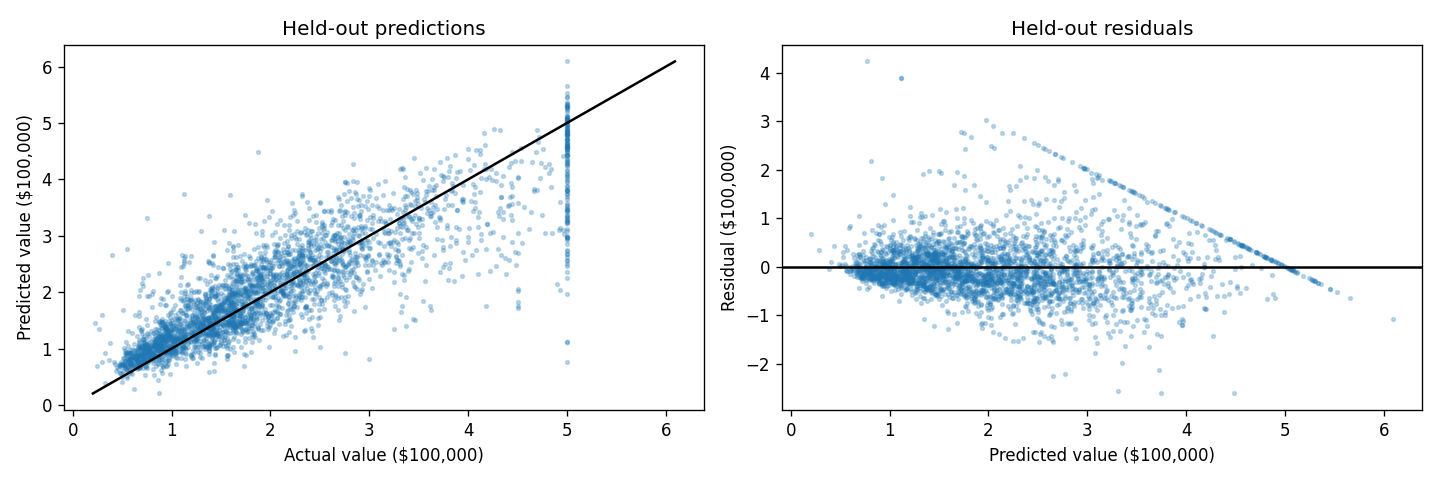

In [24]:
def regression_metrics(y,pred):
    y,pred = np.asarray(y).reshape(-1),np.asarray(pred).reshape(-1)
    residual = y-pred
    mse = float(np.mean(residual**2))
    return {'mse':mse,'rmse':float(np.sqrt(mse)),'mae':float(np.mean(np.abs(residual))),
            'r2':float(1-np.sum(residual**2)/np.sum((y-y.mean())**2))}

metrics = {}
for split in ['train','val','test']:
    y_original = data['y_'+split]*normalization['y_std']+normalization['y_mean']
    predicted = model.loss(data['X_'+split]).ravel()*normalization['y_std']+normalization['y_mean']
    metrics[split] = regression_metrics(y_original,predicted)
    if split=='test':
        test_actual,test_predicted = y_original,predicted
        mean_baseline = np.full_like(y_original,normalization['y_mean'])
        baseline_metrics = regression_metrics(y_original,mean_baseline)
print('Regression metrics (original target units):',metrics)
print('Test training-mean baseline:',baseline_metrics)
print('Best validation epoch:',solver.best_epoch)
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(solver.loss_history);axes[0].set_title('Minibatch MSE + L2');axes[0].set_xlabel('Update');axes[0].set_ylabel('Objective (standardized target)')
axes[1].plot(solver.train_mse_history,label='train');axes[1].plot(solver.val_mse_history,label='validation')
axes[1].set_title('Epoch regression error');axes[1].set_xlabel('Epoch');axes[1].set_ylabel('MSE (standardized target)');axes[1].legend()
fig.tight_layout();fig.savefig('results/training_curves.png',dpi=140);plt.show()
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].scatter(test_actual,test_predicted,s=5,alpha=.25)
lo,hi=min(test_actual.min(),test_predicted.min()),max(test_actual.max(),test_predicted.max())
axes[0].plot([lo,hi],[lo,hi],color='black');axes[0].set_xlabel('Actual value ($100,000)');axes[0].set_ylabel('Predicted value ($100,000)');axes[0].set_title('Held-out predictions')
axes[1].scatter(test_predicted,test_actual-test_predicted,s=5,alpha=.25);axes[1].axhline(0,color='black')
axes[1].set_xlabel('Predicted value ($100,000)');axes[1].set_ylabel('Residual ($100,000)');axes[1].set_title('Held-out residuals')
fig.tight_layout();fig.savefig('results/test_diagnostics.png',dpi=140);plt.show()


## Interpretation

Training/validation curves reveal learning progress and divergence. The diagonal in predicted-vs-actual plots represents perfect predictions; residual patterns reveal systematic error. The test score describes one random split of historical census block groups. It is not an assessment of future prices or a spatially separated evaluation. The framework implements regression only; sigmoid is checked independently but hidden network layers use ReLU.
